# Compare BERTopic, LDA, and human-review results

Here we compare the two methods using the measures planned in [PR2](../../progress-report-2/pr2-submission.tex):
coherence, keyword diversity, runtime, topic overlap, publication patterns, and human ratings.
The human review tells us how well each model's topic labels fit the articles.

Run modern notebooks 01–03 and record the team's model choice first. We also need Laura's four
LDA export files. This notebook reads the saved results without refitting either model. Missing
inputs show as pending; files that do not match the dataset or selected runs cause an error.

We first compare the model results, then prepare the review files once both sets of labels are
final. After both reviewers finish, we add their results to the comparison table and write our
interpretation.

Results are saved in `modern-methods/Results/comparison/<modern-run>/`. LDA inputs are in
`classical-methods/results/`. The manifest files record which data and model runs were
used, so we can check that the results belong together.

In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'pyproject.toml').exists())
ROOT = REPO/'final-project/code/modern-methods'
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT.parent))
from shared.corpus import load_corpus, corpus_hash, digest, write_json
from shared import evaluation as ev
from src import artifacts as a
from src.reviewer import load_session
OUT = ROOT/'Results/modern'
CLASSICAL = ROOT.parent/'classical-methods/results'  # Authoritative saved LDA exports.
sys.path.insert(0, str(ROOT.parent/'comparison'))
from report_helpers import validate_mixtures, draft_inventory, comparison_classical_labels
COMPARISON_ROOT = ROOT/'Results/comparison'
COMPARISON_ROOT.mkdir(parents=True, exist_ok=True)

Matplotlib is building the font cache; this may take a moment.


In [2]:
df = load_corpus()
reservation = json.loads((OUT/'review_sample.json').read_text())
if reservation['corpus_hash'] != corpus_hash(df):
    raise ValueError('Review reservation belongs to a different corpus')
if len(reservation['article_ids']) != len(set(reservation['article_ids'])) or not set(reservation['article_ids']).issubset(df.article_id):
    raise ValueError('Invalid reserved review IDs')
experiments = pd.read_csv(OUT/'experiments.csv')
selection = a.selection_record(OUT, df, experiments.run_id.tolist())
print(f'Common corpus: {len(df):,} articles; {df.publication.nunique()} publications.')
print(f'Reserved review sample: {len(reservation["article_ids"])} articles, independent of development review.')

Common corpus: 7,332 articles; 25 publications.
Reserved review sample: 100 articles, independent of development review.


## 1. Load the selected BERTopic run

The choice comes from notebook 02. We check that its saved files match the shared dataset and
reserved review sample. Keyword labels can appear in the tables while naming is unfinished,
but we should confirm the labels before writing conclusions about specific themes.

In [3]:
modern = terms = inventory = labels = modern_manifest = None
labels_ready = False
if selection is None:
    print('Modern selection pending team article review; no run is chosen automatically.')
else:
    run_id = selection['run_id']
    folder = OUT/'runs'/run_id
    modern_manifest = json.loads((folder/'manifest.json').read_text())
    identity = modern_manifest['identity']
    if identity['corpus_hash'] != corpus_hash(df) or identity['reservation_hash'] != digest(reservation):
        raise ValueError('Modern run corpus or review reservation differs')
    for name in ['assignments.csv','terms.csv','topics.csv','representative_ids.csv','coherence.csv']:
        if hashlib.sha256((folder/name).read_bytes()).hexdigest() != modern_manifest['files'][name]:
            raise ValueError(f'Modern export changed: {name}')
    modern = pd.read_csv(folder/'assignments.csv',dtype={'article_id':str,'run_id':str})
    modern = ev.aligned_assignments(df, modern)
    if not modern.model.eq('bertopic').all() or not modern.run_id.eq(run_id).all():
        raise ValueError('Modern assignments do not describe the selected run')
    terms = pd.read_csv(folder/'terms.csv')
    selected_folder = OUT/'selected'/run_id
    labels = a.labels_table(folder, selected_folder, dict(run_id=run_id,corpus_hash=corpus_hash(df),run_identity_hash=digest(identity)))
    labels_ready = bool(len(labels) and labels.confirmed.astype(str).str.lower().eq('true').all())
    inventory = a.topic_inventory(folder, selected_folder, len(df), labels)
    display(inventory[['topic_id','label','label_status','count','prevalence']])
    print('Modern labels:', 'confirmed' if labels_ready else 'pending team confirmation')

,topic_id,label,label_status,count,prevalence
0,-1,Unassigned,not a topic,1323,0.180442
1,0,"Tesla Autopilot development, claims and safety",team confirmed,538,0.073377
2,1,Waymo autonomous-driving development and deplo...,team confirmed,438,0.059738
3,2,Uber-Waymo trade-secret litigation,team confirmed,334,0.045554
4,3,AV safety and deployment readiness,team confirmed,302,0.041189
...,...,...,...,...,...
66,65,Uber-Volvo autonomous XC90 partnership,team confirmed,27,0.003682
67,66,Automaker mergers and alliances,team confirmed,27,0.003682
68,67,Hill.TV Boundless technology interview coverage,team confirmed,27,0.003682
69,68,Las Vegas autonomous rides,team confirmed,26,0.003546


Modern labels: confirmed


## Load the saved LDA results

Read `assignments.csv`, `terms.csv`, `topics.csv`, and `manifest.json` from
`../classical-methods/results/` without changing them. The assignments must include each
shared article once, and each topic needs ten ranked single-word terms. The manifest's
corpus hash must match our dataset. Keep LDA's full topic mixtures separately.

Comparison-specific descriptive names and their approval/reservation metadata live in
`Results/comparison/<modern-run>/classical_labels.csv` and `classical_labels_identity.json`.
They are bound to the original exports by hashes and applied only in memory for comparison
and review. Without confirmed comparison labels (or already-confirmed source labels),
numerical comparison can run but human review stays pending. No classical file needs editing.

The source manifest can include `timings` (seconds for each stage) and `environment`
(hardware and software). Missing timings stay missing; we do not substitute older PR2 values.


In [4]:
required = ['assignments.csv','terms.csv','topics.csv','manifest.json']
missing = [name for name in required if not (CLASSICAL/name).exists()]
classical = classical_terms = classical_topics = classical_manifest = None
classical_labels_ready = False
classical_validation = {}
classical_label_files = {}
COMPARISON = None
if missing:
    print('LDA handoff pending:', ', '.join(missing))
else:
    classical, classical_terms, classical_topics = ev.validate_classical(CLASSICAL, df.article_id.tolist())
    classical_manifest = json.loads((CLASSICAL/'manifest.json').read_text())
    if classical_manifest.get('corpus_hash') != corpus_hash(df):
        raise ValueError('LDA corpus hash differs')
    if classical_manifest.get('review_reservation_hash') not in [None, digest(reservation)]:
        raise ValueError('Classical review reservation differs from the frozen shared sample')
    classical_labels_ready = (classical_manifest.get('labels_confirmed') is True and
                              classical_manifest.get('review_reservation_hash') == digest(reservation))
    if classical_labels_ready and classical_topics.label.fillna('').str.strip().eq('').any():
        raise ValueError('Confirmed classical labels cannot be blank')

    if selection is not None:
        classical_topics, comparison_labels_ready, classical_label_files = comparison_classical_labels(
            COMPARISON_ROOT/selection['run_id'], CLASSICAL, classical_topics,
            classical_manifest, digest(reservation))
        if classical_label_files:
            classical_labels_ready = comparison_labels_ready

    timings = classical_manifest.get('timings', {})
    if not isinstance(timings, dict) or any(isinstance(v, bool) or not isinstance(v, (int, float)) or not np.isfinite(v) or v < 0 for v in timings.values()):
        raise ValueError('LDA timings must map stage names to finite nonnegative seconds')
    top = classical_terms.query('rank <= 10')
    if top.duplicated(['topic_id','term']).any() or top.term.astype(str).str.contains(r'\s').any():
        raise ValueError('LDA top-ten terms must be distinct unigrams within each topic')
    classical_validation = validate_mixtures(CLASSICAL, classical, classical_topics)
    if classical_manifest.get('run_id', str(classical.run_id.iloc[0])) != str(classical.run_id.iloc[0]):
        raise ValueError('LDA manifest run ID differs from assignments')


In [5]:
# Guard output identity before writing tables or touching a review packet.
COMPARISON = None
if modern is not None and classical is not None:
    COMPARISON = COMPARISON_ROOT/selection['run_id']
    comparison_identity = dict(
        corpus_hash=corpus_hash(df), modern_run=selection['run_id'],
        classical_run=str(classical.run_id.iloc[0]), classical_manifest_hash=digest(classical_manifest),
        modern_identity_hash=digest(modern_manifest['identity']),
        modern_files=modern_manifest['files'],
        classical_files={name:hashlib.sha256((CLASSICAL/name).read_bytes()).hexdigest() for name in required},
        reservation_hash=digest(reservation))
    if classical_label_files:
        comparison_identity['classical_label_files'] = classical_label_files
    binding = COMPARISON/'comparison_identity.json'
    if binding.exists():
        previous = json.loads(binding.read_text())
        if any(comparison_identity.get(key) != value for key, value in previous.items()):
            raise ValueError('Comparison belongs to different model exports; preserve old results before changing runs')
    COMPARISON.mkdir(parents=True, exist_ok=True)
    write_json(binding, comparison_identity)
else:
    print('Joint comparison pending selected modern model and validated LDA exports.')

## 2. Compare coherence and keyword diversity

We calculate $c_v$ coherence for both models using the same articles, tokenizer, top ten words,
and 110-token window. Words missing from the reference vocabulary are left out of the score.
We report vocabulary coverage and per-topic scores along with the mean.

Keyword diversity is the number of unique top-ten words divided by the total number of top-ten
word slots across topics. BERTopic's unassigned category (−1) is excluded from both measures.
These scores help us compare topics, but do not measure accuracy against known correct labels.

In [6]:
comparison_metrics = None
if COMPARISON is not None:
    texts, dictionary = ev.reference_texts(df)
    metric_rows = []
    for model_name, model_terms, assignments in [('bertopic',terms,modern),('lda',classical_terms,classical)]:
        scores = ev.coherence(model_terms, texts, dictionary)
        scores.to_csv(COMPARISON/f'{"classical" if model_name == "lda" else "modern"}_coherence.csv',index=False)
        top = model_terms.query('topic_id >= 0 and rank <= 10')
        metric_rows.append(dict(model=model_name, topic_count=top.topic_id.nunique(),
            coherence=scores.coherence.mean(), vocabulary_coverage=scores.vocabulary_coverage.mean(),
            keyword_diversity=top.term.nunique()/len(top), outlier_fraction=assignments.topic_id.eq(-1).mean()))
    comparison_metrics = pd.DataFrame(metric_rows)
    comparison_metrics.to_csv(COMPARISON/'model_metrics.csv',index=False)
    write_json(COMPARISON/'classical_validation.json', classical_validation)
    # Drafts are separate from immutable exports and never authorize review packets.
    for name, model_topics, model_terms, rep_path in [
        ('modern', pd.read_csv(OUT/'runs'/selection['run_id']/'topics.csv'), terms,
         OUT/'runs'/selection['run_id']/'representative_ids.csv'),
        ('classical', classical_topics, classical_terms, CLASSICAL/'representatives.csv')]:
        if rep_path.exists():
            draft_inventory(name, model_topics, model_terms,
                pd.read_csv(COMPARISON/f'{name}_coherence.csv'),
                pd.read_csv(rep_path, dtype={'article_id':str}), COMPARISON, reservation['article_ids'])
    display(comparison_metrics)
else:
    print('Shared quantitative metrics pending both model exports.')

,model,topic_count,coherence,vocabulary_coverage,keyword_diversity,outlier_fraction
0,bertopic,70,0.704696,1.0,0.651429,0.180442
1,lda,40,0.655233,1.0,0.710000,0.000000


## 3. Compare topics and article assignments

The heatmap shows Jaccard overlap between each pair of top-ten word sets: **LDA topics are rows
and BERTopic topics are columns**. Topic −1 is excluded. We list the best match for each LDA
topic and show any ties. More than one LDA topic can match the same BERTopic topic.

Shared words suggest a possible connection, but we need to read example articles to check it.
Likewise, zero word overlap does not necessarily mean two topics are unrelated. Topic numbers
are separate for each model.

The assignment table counts how often the models put the same articles in each pair of topics,
including BERTopic's unassigned category. For LDA, we use each article's dominant topic.

,lda_topic,modern_topic,jaccard,tied_modern_topics,interpretation
0,0,3,0.250000,3,"Best lexical match, not semantic equivalence"
1,1,67,0.666667,67,"Best lexical match, not semantic equivalence"
2,2,18,0.333333,18,"Best lexical match, not semantic equivalence"
3,3,32,0.538462,32,"Best lexical match, not semantic equivalence"
4,4,20,0.538462,20,"Best lexical match, not semantic equivalence"
5,5,9,0.111111,9 | 42,"Best lexical match, not semantic equivalence"
6,6,3,0.052632,3 | 19 | 23 | 61,"Best lexical match, not semantic equivalence"
7,7,2,0.666667,2,"Best lexical match, not semantic equivalence"
8,8,57,0.250000,57,"Best lexical match, not semantic equivalence"
9,9,0,0.428571,0,"Best lexical match, not semantic equivalence"


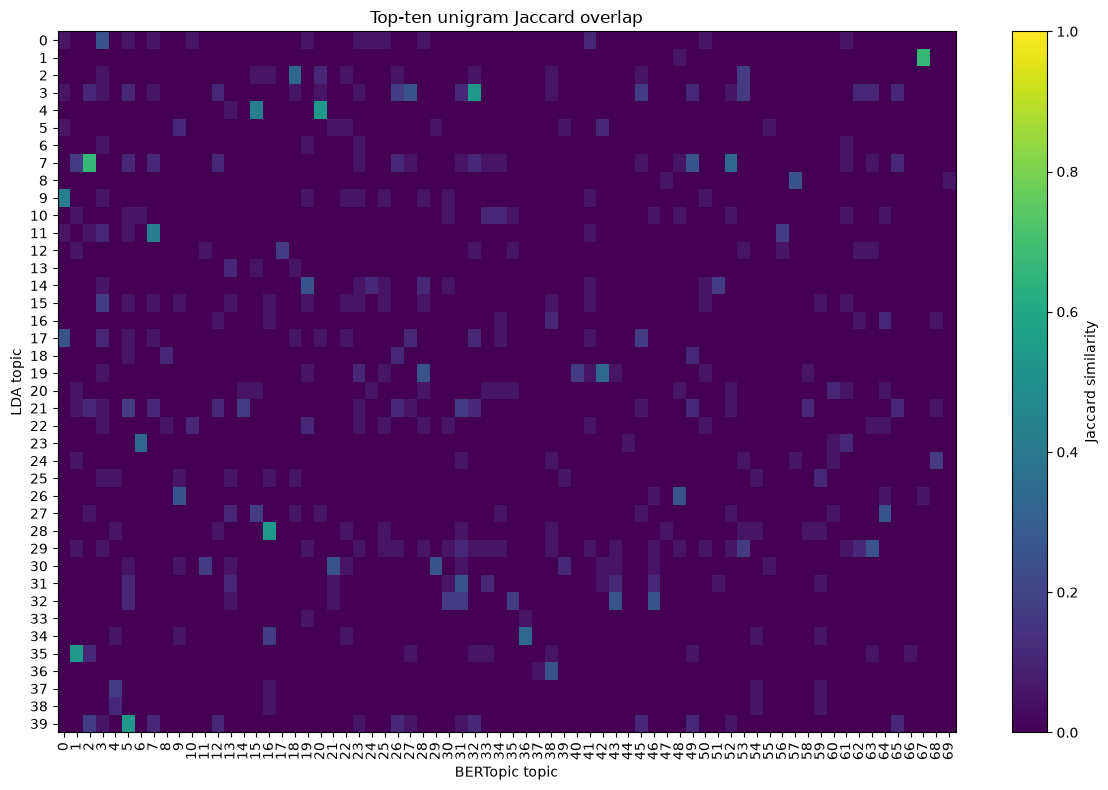

topic_id_modern,-1,0,1,2,3,4,5,6,7,8,...,60,61,62,63,64,65,66,67,68,69
topic_id_lda,,,,,,,,,,,,,,,,,,,,,
0,174,58,34,2,135,1,0,6,12,11,...,0,9,5,0,0,0,0,0,4,11
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,27,0,0
2,136,3,11,0,64,3,0,5,0,4,...,0,0,3,1,0,0,0,0,0,0
3,61,0,6,0,4,0,4,4,2,0,...,0,0,0,0,0,11,0,0,0,0
4,14,1,2,0,0,1,1,0,2,0,...,0,0,0,0,0,0,0,0,0,0
5,49,15,1,0,0,1,1,0,1,1,...,0,0,0,0,0,1,5,0,0,1
6,48,2,7,0,34,69,1,6,1,1,...,0,4,0,0,0,0,0,0,0,0
7,17,1,4,319,0,0,4,0,12,1,...,0,0,0,0,1,1,0,0,0,0
8,5,0,1,0,0,5,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0


In [7]:
best = None
if COMPARISON is not None:
    matrix = ev.jaccard_table(classical_terms, terms)
    matrix.index.name = 'lda_topic'
    matrix.columns.name = 'modern_topic'
    matrix.to_csv(COMPARISON/'jaccard.csv')
    best = pd.DataFrame({'lda_topic':matrix.index,'modern_topic':matrix.idxmax(axis=1).values,'jaccard':matrix.max(axis=1).values})
    best['tied_modern_topics'] = [' | '.join(map(str,row.index[row.eq(row.max())])) for _,row in matrix.iterrows()]
    best['interpretation'] = np.where(best.jaccard.eq(0),'No lexical overlap; numeric tie is arbitrary','Best lexical match, not semantic equivalence')
    best.to_csv(COMPARISON/'best_lexical_matches.csv',index=False)
    display(best)
    fig, ax = plt.subplots(figsize=(12,8))
    image = ax.imshow(matrix,aspect='auto',vmin=0,vmax=1)
    ax.set_yticks(range(len(matrix)),matrix.index)
    ax.set_xticks(range(len(matrix.columns)),matrix.columns,rotation=90)
    ax.set(xlabel='BERTopic topic',ylabel='LDA topic',title='Top-ten unigram Jaccard overlap')
    fig.colorbar(image,ax=ax,label='Jaccard similarity')
    fig.tight_layout()
    for extension in ['png','pdf']: fig.savefig(COMPARISON/f'jaccard.{extension}',dpi=180)
    plt.show()
    plt.close(fig)
    paired = modern[['article_id','topic_id']].merge(classical[['article_id','topic_id']],on='article_id',validate='one_to_one',suffixes=('_modern','_lda'))
    contingency = pd.crosstab(paired.topic_id_lda,paired.topic_id_modern)
    contingency.to_csv(COMPARISON/'assignment_contingency.csv')
    display(contingency)
else:
    print('Topic overlap pending both model exports.')

## 4. Compare publication patterns

Each heatmap shows the 15 largest topics plus unassigned articles for publications with at least
50 articles. Publication sample sizes appear beside their names. LDA assigns every article, so
its unassigned column is zero. The full CSV tables include all 25 publications and all topics.

Shares use every article from a publication in the denominator. The topics shown in the figure
may therefore add to less than 100%.

The matched-topic table puts each LDA topic's publication shares beside those of its best
keyword match in BERTopic. It includes ties and zero-overlap matches. Use it to look for broad
patterns, then check the articles. The topics may differ in scope, so subtracting their shares
would not necessarily measure a difference in the same theme. Date coverage may also affect
publication differences.

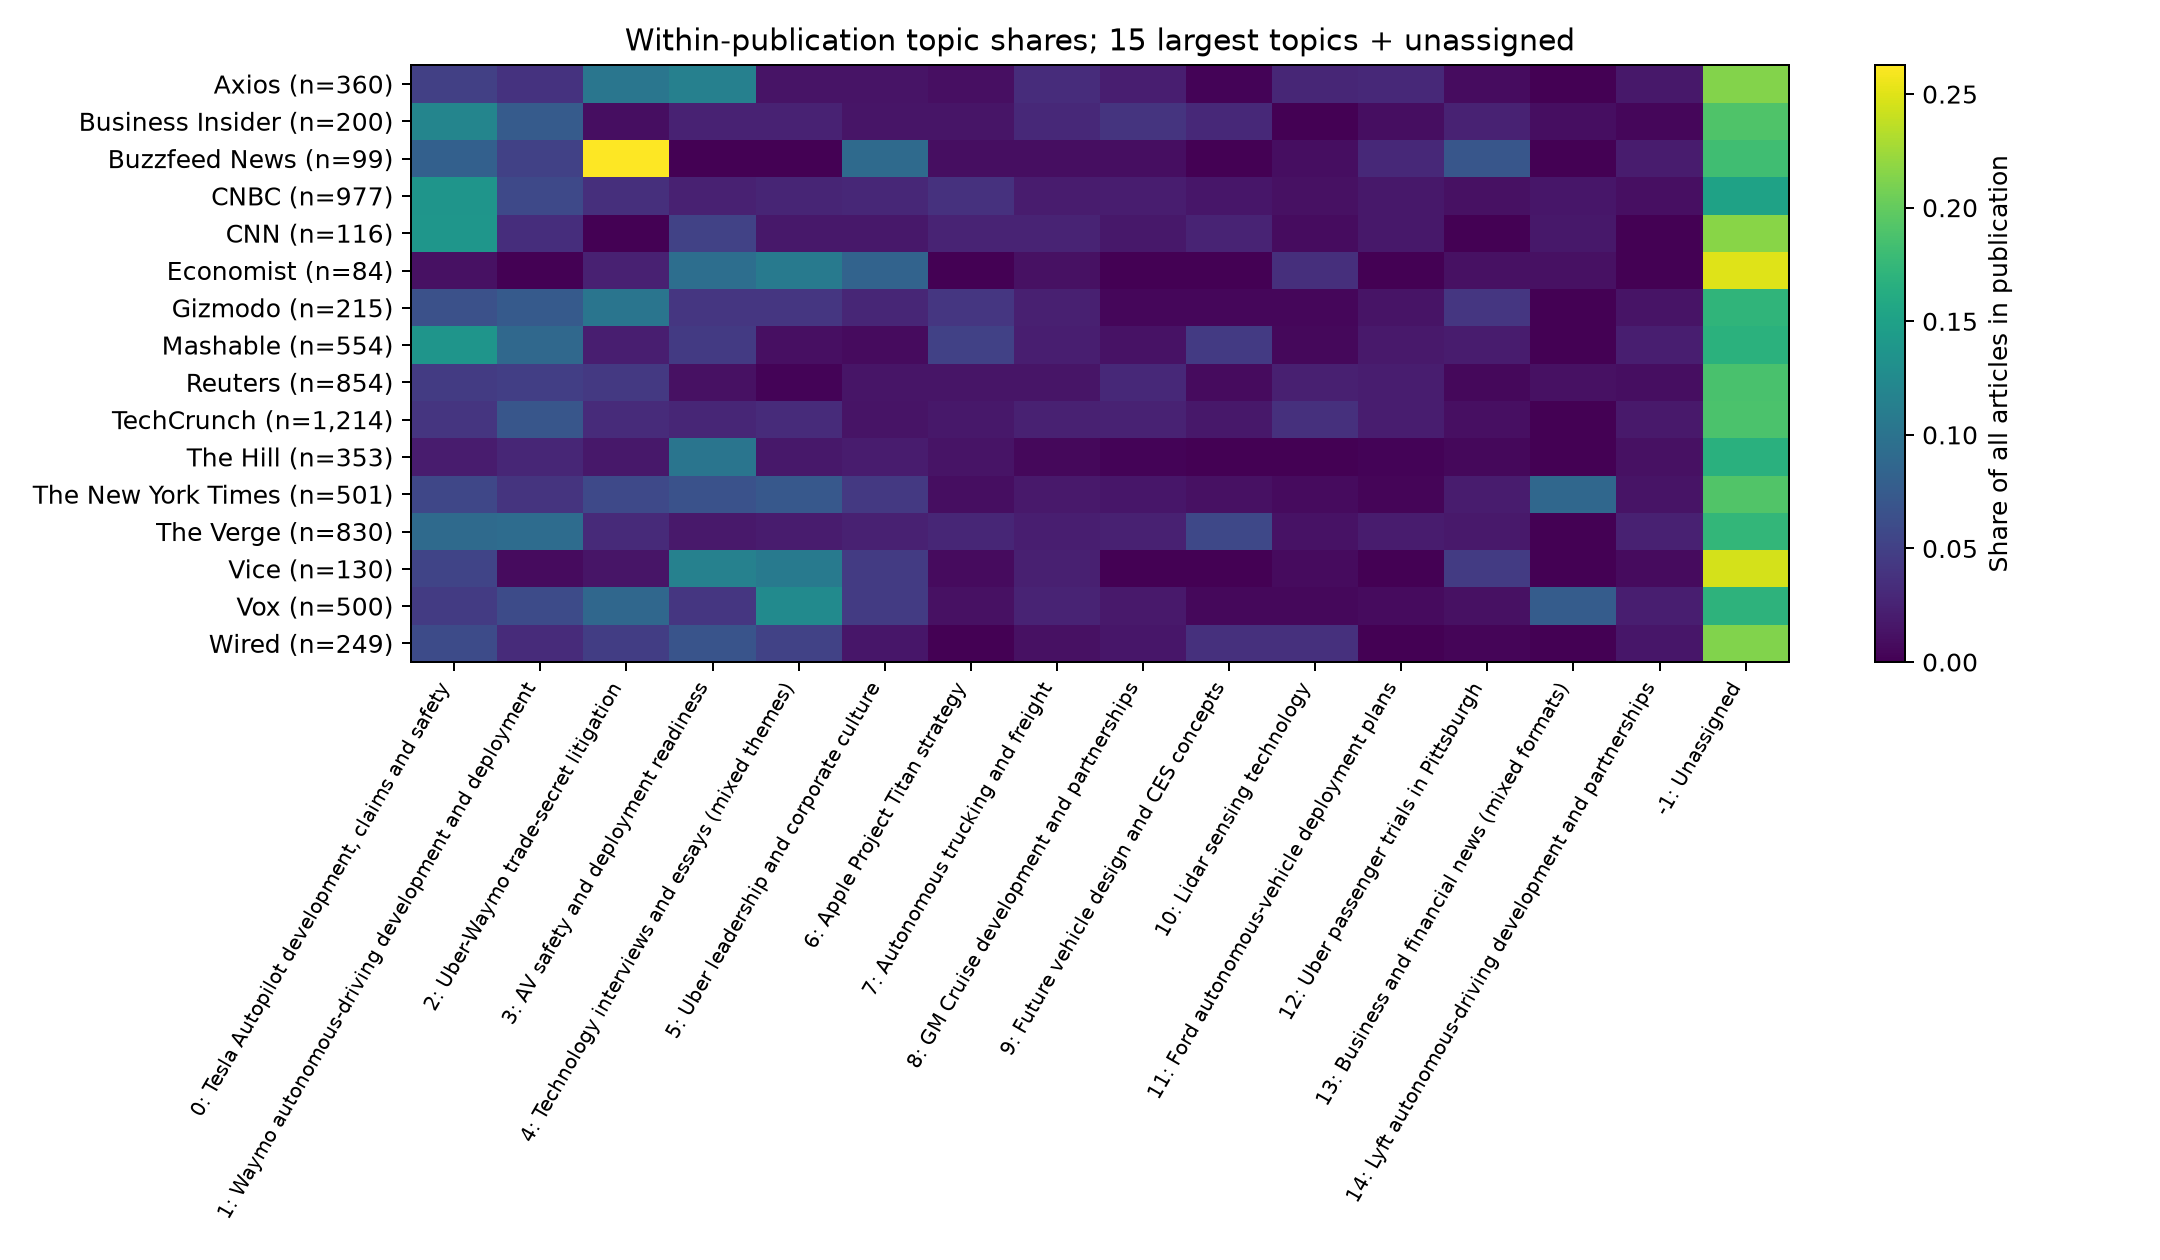

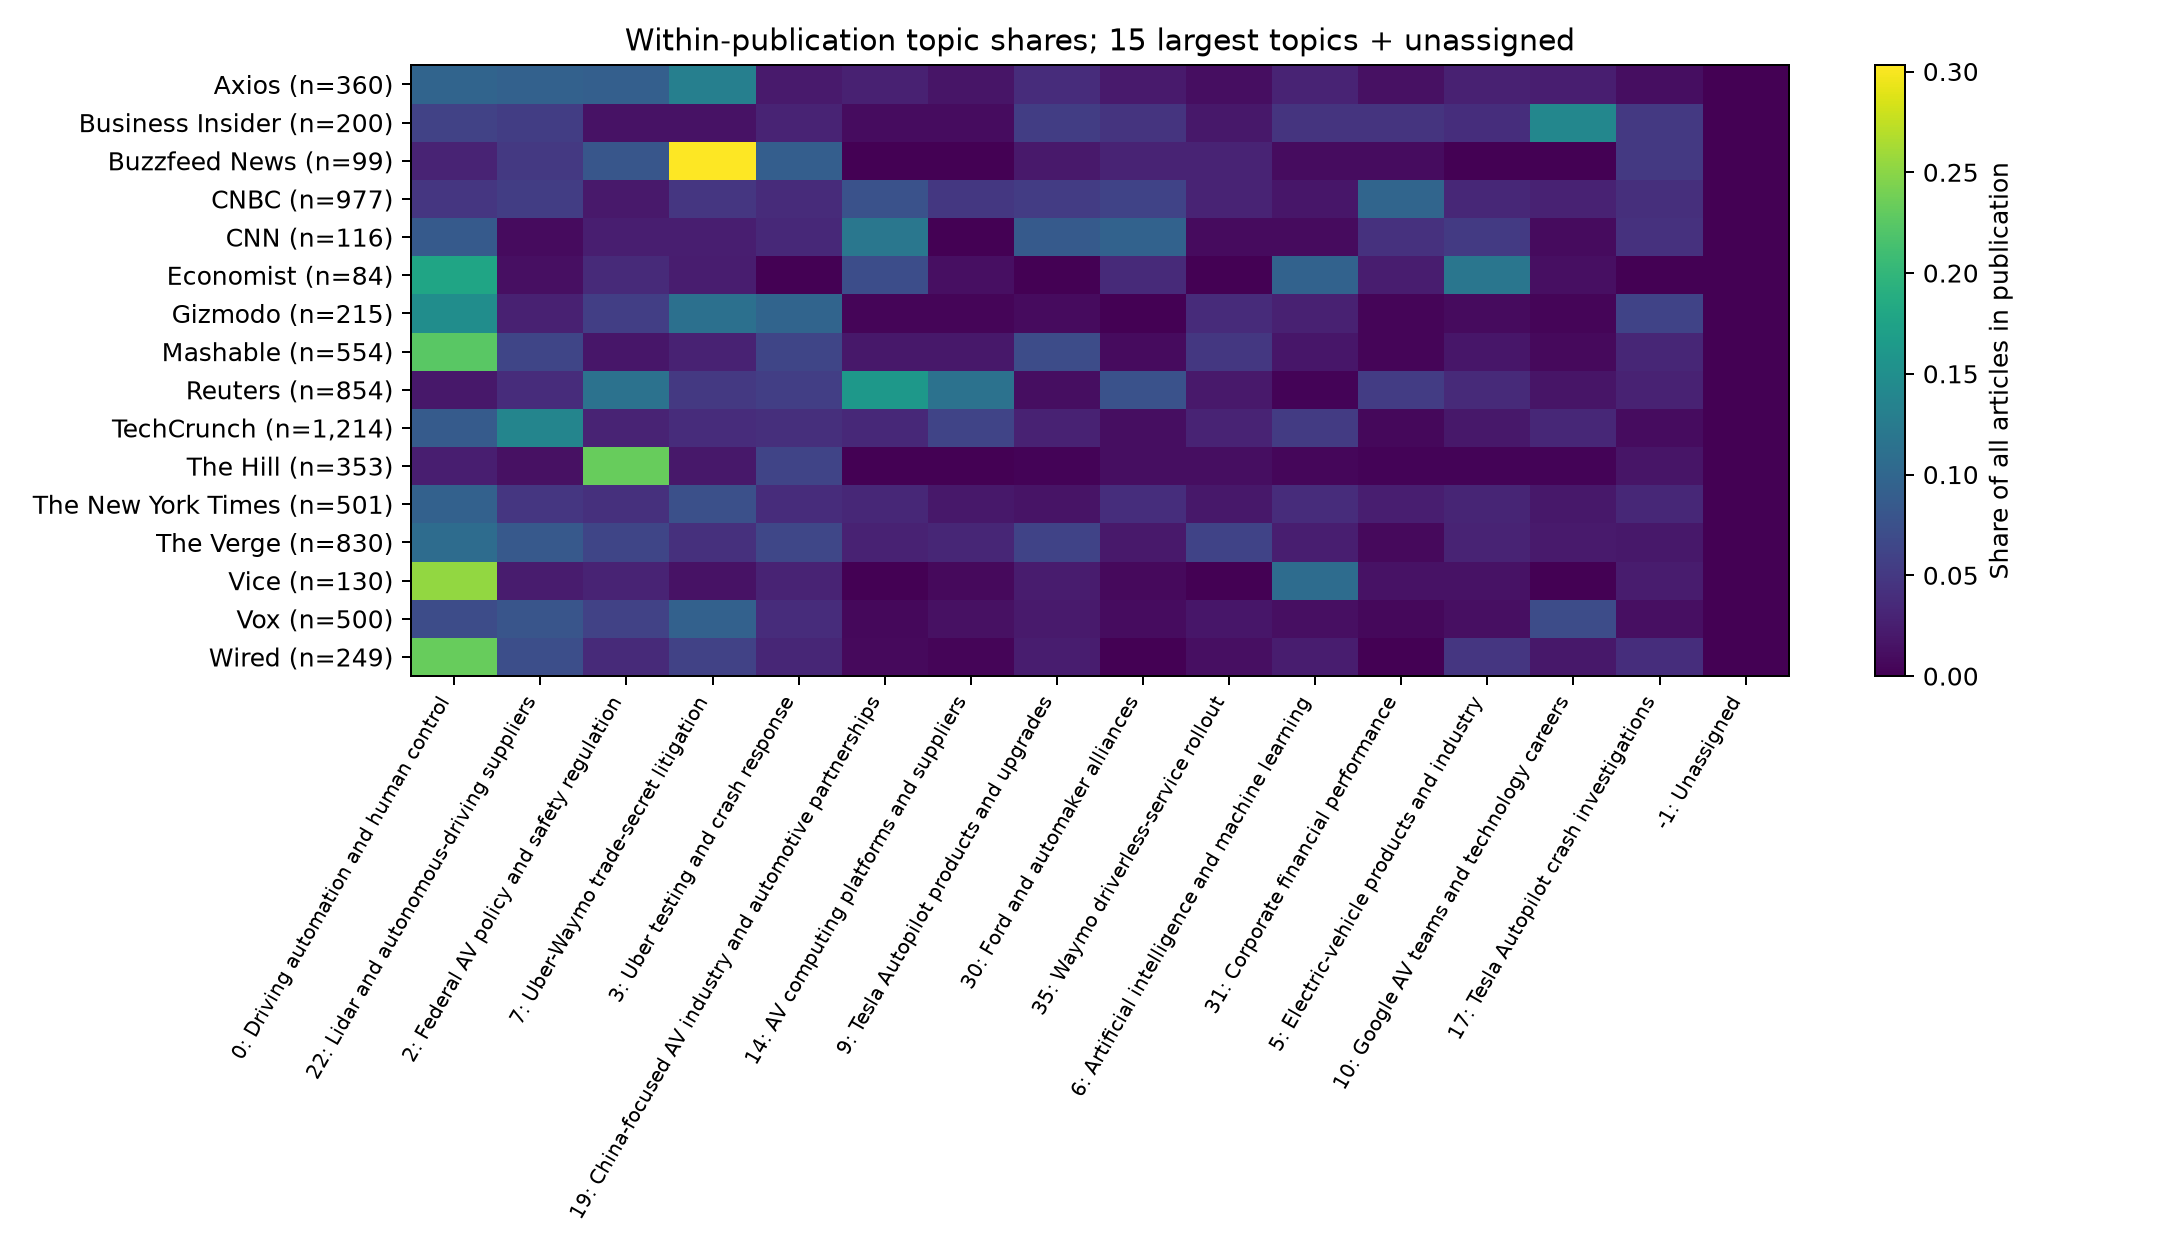

,publication,article_count,lda_topic,modern_topic,jaccard,tied_modern_topics,interpretation,lda_proportion,modern_proportion
0,Axios,360,0,3,0.25,3,"Best lexical match, not semantic equivalence",0.097222,0.113889
1,Business Insider,200,0,3,0.25,3,"Best lexical match, not semantic equivalence",0.060000,0.025000
2,Buzzfeed News,99,0,3,0.25,3,"Best lexical match, not semantic equivalence",0.030303,0.000000
3,CNBC,977,0,3,0.25,3,"Best lexical match, not semantic equivalence",0.048106,0.024565
4,CNN,116,0,3,0.25,3,"Best lexical match, not semantic equivalence",0.086207,0.051724
5,Economist,84,0,3,0.25,3,"Best lexical match, not semantic equivalence",0.178571,0.095238
6,Fox News,23,0,3,0.25,3,"Best lexical match, not semantic equivalence",0.086957,0.000000
7,Gizmodo,215,0,3,0.25,3,"Best lexical match, not semantic equivalence",0.148837,0.041860
8,Hyperallergic,1,0,3,0.25,3,"Best lexical match, not semantic equivalence",0.000000,0.000000
9,Mashable,554,0,3,0.25,3,"Best lexical match, not semantic equivalence",0.225632,0.045126


In [8]:
if COMPARISON is not None:
    publication_tables = {}
    for name, assignments, topic_labels in [
        ('modern',modern,dict(zip(inventory.topic_id,inventory.label))),
        ('classical',classical,dict(zip(classical_topics.topic_id,classical_topics.label)))]:
        counts, proportions = ev.publication_exports(df, assignments, COMPARISON/name, topic_labels)
        publication_tables[name] = (counts, proportions)
        plot = COMPARISON/name/'publication_proportions.png'
        if plot.exists(): display(Image(filename=str(plot)))
    rows = []
    for match in best.itertuples():
        for publication in publication_tables['classical'][1].index:
            lda_share = publication_tables['classical'][1].loc[publication].get(match.lda_topic, 0.0)
            modern_share = publication_tables['modern'][1].loc[publication].get(match.modern_topic, 0.0)
            rows.append(dict(publication=publication,
                article_count=int(publication_tables['classical'][0].loc[publication].sum()),
                lda_topic=match.lda_topic, modern_topic=match.modern_topic, jaccard=match.jaccard,
                tied_modern_topics=match.tied_modern_topics, interpretation=match.interpretation,
                lda_proportion=lda_share, modern_proportion=modern_share))
    matched_shares = pd.DataFrame(rows)
    matched_shares.to_csv(COMPARISON/'matched_publication_proportions.csv',index=False)
    display(matched_shares.head(10))
else:
    print('Cross-model publication comparison pending both model exports.')

## 5. Compare runtime and seed stability

BERTopic's fitting time includes UMAP, HDBSCAN, and topic keywords. Evaluation is timed separately.
Creating embeddings is a one-time cost shared by the six fits. We report it separately rather
than adding it to every run.

Check the hardware, software, and stages included before comparing runtimes. Loading saved
embeddings is different from creating them, and missing LDA timings prevent a full cost comparison.

For seed stability, use the current results from each method. Modern ARI includes only articles
assigned in both runs, so report the fraction compared and agreement on unassigned articles too.
The older PR2 seed results are not results for the current runs.

In [9]:
runtime_table = None
if COMPARISON is not None:
    modern_metrics = modern_manifest['metrics']
    runtime = [dict(model='bertopic',stage='fitting and representation',seconds=modern_metrics['fitting_representation_seconds']),
               dict(model='bertopic',stage='evaluation',seconds=modern_metrics['evaluation_seconds'])]
    for stage, seconds in classical_manifest.get('timings',{}).items():
        runtime.append(dict(model='lda',stage=stage,seconds=seconds))
    embedding_context = None
    execution_path = OUT/'embedding_execution.json'
    if execution_path.exists():
        pointer = json.loads((OUT/'embedding_pointer.json').read_text())
        if pointer['array_hash'] != modern_manifest['identity']['embedding_hash'] or pointer['manifest']['article_ids'] != df.article_id.tolist():
            raise ValueError('Embedding timing context does not match the selected modern run')
        embedding_context = json.loads(execution_path.read_text())
        first = embedding_context['first_execution']
        for key in ['model_load_download_seconds','embedding_seconds']:
            runtime.append(dict(model='bertopic',stage=f'shared embedding preparation: {key}',seconds=first[key]))
    else:
        print('Embedding runtime context unavailable; do not treat missing costs as zero.')
    runtime_table = pd.DataFrame(runtime)
    runtime_table.to_csv(COMPARISON/'runtime_comparison.csv',index=False)
    write_json(COMPARISON/'runtime_context.json', dict(
        modern=modern_manifest.get('environment',{}), classical=classical_manifest.get('environment',{}),
        classical_manifest=str(CLASSICAL/'manifest.json'), embedding=embedding_context,
        note='Recorded stages only; missing hardware, timing, or stage definitions must be supplied before cost ranking.'))
    display(runtime_table)
    if not classical_manifest.get('timings'): print('LDA runtime pending measured stage timings.')
    stability_path = OUT/'selected'/selection['run_id']/'stability.csv'
    stability_tables = []
    for model_name, path in [('bertopic', stability_path), ('lda', CLASSICAL/'stability.csv')]:
        if path.exists():
            table = pd.read_csv(path).assign(model=model_name)
            stability_tables.append(table)
            display(table)
        else:
            print(f'{model_name} seed checks unavailable.')
    if stability_tables:
        pd.concat(stability_tables, ignore_index=True).to_csv(COMPARISON/'seed_stability.csv', index=False)
else:
    print('Runtime comparison pending both model exports.')

,model,stage,seconds
0,bertopic,fitting and representation,10.049607
1,bertopic,evaluation,22.608060
2,bertopic,shared embedding preparation: model_load_downl...,0.306335
3,bertopic,shared embedding preparation: embedding_seconds,100.676937


LDA runtime pending measured stage timings.


,seed,adjusted_rand_index,evaluated_count,evaluated_fraction,outlier_agreement,split_merge_threshold,model
0,7,0.961365,5697,0.777005,0.910393,At least two overlaps each covering >=10% of t...,bertopic
1,21,0.976049,5678,0.774414,0.911348,At least two overlaps each covering >=10% of t...,bertopic


,seed,adjusted_rand_index,evaluated_count,evaluated_fraction,outlier_agreement,model
0,7,0.323033,7332,1.0,1.0,lda
1,21,0.346897,7332,1.0,1.0,lda


## 6. Prepare the human-review files

Both models and their labels must be final before this step. We use the original reserved
sample, and Laura must confirm that those articles were not used for LDA topic naming. The saved
review files fix the article IDs, assignments, and labels for the review. Rerunning keeps existing
answers and stops if those inputs have changed.

Give each person their [reviewer 1](../human-review/reviewer_1.ipynb) or
[reviewer 2](../human-review/reviewer_2.ipynb) notebook. Each person reviews both models for the
same 100 articles: 200 article–model pairs. They can see which model produced each label, so the
review is not blinded. Use the [coordinator notebook](../human-review/review_coordinator.ipynb)
to check progress. Reviewers should finish independently before discussing their scores.

The fit scale runs from **1 (unrelated or misleading)** to **5 (a clear fit to a central theme)**.
The reviewer notebooks explain each score. Unassigned BERTopic articles get no numeric fit score;
reviewers still mark relevance and label ambiguity and can add notes.

These articles were included in model fitting. They were set aside only from model-selection
review and topic naming.

In [10]:
review_folder = None
human_status = ('Pending team-confirmed labels and independent ratings.' if COMPARISON is not None
                else 'Pending selected modern model and complete LDA handoff.')
if COMPARISON is not None and labels_ready and classical_labels_ready:
    lookup = {('bertopic',int(row.topic_id)):row.proposed_label for row in labels.itertuples()}
    lookup.update({('lda',int(row.topic_id)):row.label for row in classical_topics.itertuples()})
    review_folder = COMPARISON/'human_review'
    packet = ev.review_packets(df, modern, classical, review_folder, lookup,
                               article_ids=reservation['article_ids'],reservation=reservation)
    human_status = 'Packet ready; independent ratings pending.'
    print('Frozen packet:', review_folder)
else:
    print(human_status)
    if classical is not None and not classical_labels_ready:
        print('Confirm comparison-owned LDA labels and the shared review reservation; leave the classical exports unchanged.')

Frozen packet: /Users/marykate/Desktop/F26/DataMiningProject/final-project/code/modern-methods/Results/comparison/n30_c25_s42/human_review


## 7. Add the human-review results

Once both reviewers finish, set `RUN_HUMAN_SUMMARY = True` and rerun the notebook. The code checks
the answer files against the saved review packet. Incomplete reviews stay pending.

We report each reviewer's mean score, the share of ratings that match exactly, the share within
one point, and quadratic-weighted Cohen's kappa. Kappa measures agreement beyond chance and gives
larger disagreements more weight. Its 95% interval uses 1,000 bootstrap resamples of articles,
keeping the two reviewers' ratings paired.

Modern outliers are excluded from fit means and agreement. We report their number and share
separately and discuss the reviewers' notes. This means the two models can have different numbers
of rated articles. Undefined kappa is left blank, and the output reports how many bootstrap
resamples gave a usable value. Two team reviewers provide a small, subjective evaluation.

In [11]:
# Enable only after both reviewers finish independently.
RUN_HUMAN_SUMMARY = False
human_summary = None
if review_folder is not None:
    # Validate files and check completion counts without displaying individual scores.
    sessions = [load_session(review_folder, reviewer) for reviewer in ['reviewer_1','reviewer_2']]
    display(pd.DataFrame([dict(reviewer=s['reviewer'],completed=int(s['complete'].sum()),total=len(s['complete'])) for s in sessions]))
    if RUN_HUMAN_SUMMARY:
        result = ev.summarize_reviews(review_folder, bootstrap_samples=1000, seed=42)
        if isinstance(result, pd.DataFrame):
            human_summary = result
            human_summary['unassigned_fraction'] = human_summary.unassigned_articles / human_summary.sample_articles
            human_status = 'complete'
            display(human_summary)
        else:
            human_status = result
    else:
        human_status = 'Pending coordinator enabling summary after both independent submissions.'
print(human_status)

pipeline_comparison = None
if comparison_metrics is not None:
    pipeline_comparison = comparison_metrics.copy()
    human_columns = ['sample_articles','rated_articles','unassigned_articles','unassigned_fraction',
                     'mean_1','mean_2','exact_agreement','within_one_agreement','weighted_kappa',
                     'kappa_ci_low','kappa_ci_high','valid_bootstrap_samples']
    if human_summary is not None:
        pipeline_comparison = pipeline_comparison.merge(human_summary[['model']+human_columns],on='model',validate='one_to_one')
    else:
        for column in human_columns: pipeline_comparison[column] = np.nan
    pipeline_comparison['human_status'] = human_status
    pipeline_comparison['fitting_representation_seconds'] = pipeline_comparison.model.map({'bertopic':modern_manifest['metrics']['fitting_representation_seconds']})
    pipeline_comparison['recorded_runtime_stages_seconds'] = pipeline_comparison.model.map({name:json.dumps(dict(zip(group.stage,group.seconds))) for name,group in runtime_table.groupby('model')})
    pipeline_comparison['runtime_detail'] = 'runtime_comparison.csv; inspect recorded stage definitions and runtime_context.json'
    pipeline_comparison.to_csv(COMPARISON/'pipeline_comparison.csv',index=False)
    display(pipeline_comparison)

,reviewer,completed,total
0,reviewer_1,0,200
1,reviewer_2,0,200


Pending coordinator enabling summary after both independent submissions.


,model,topic_count,coherence,vocabulary_coverage,keyword_diversity,outlier_fraction,sample_articles,rated_articles,unassigned_articles,unassigned_fraction,...,exact_agreement,within_one_agreement,weighted_kappa,kappa_ci_low,kappa_ci_high,valid_bootstrap_samples,human_status,fitting_representation_seconds,recorded_runtime_stages_seconds,runtime_detail
0,bertopic,70,0.704696,1.0,0.651429,0.180442,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Pending coordinator enabling summary after bot...,10.049607,"{""fitting and representation"": 10.049606709042...",runtime_comparison.csv; inspect recorded stage...
1,lda,40,0.655233,1.0,0.710000,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Pending coordinator enabling summary after bot...,NaN,NaN,runtime_comparison.csv; inspect recorded stage...


## 8. Write the comparison for the report

Use the tables and example articles to address these questions:

- Which topics seem similar across methods? Where does one method split a broad theme into smaller topics?
- Do both methods suggest similar differences between publications? Could sample size or date coverage explain a pattern?
- How well do the human scores support the topic labels? Where did reviewers disagree, and what did they find in unassigned articles?
- Do coherence, diversity, coverage, runtime, and human ratings suggest different strengths and weaknesses?

The checklist below tracks finished results and remaining work. Missing human ratings stay blank
in the combined table. We update `pr3-submission.tex` manually.

Held-out testing and comparisons over shared date ranges are still planned for the final report.
Before splitting the data, we need a rule for publication/year groups with only one article.
Preprocessing, model selection, and fitting must then use training data only. We also need the
actual PR2 feedback before responding to it. Topic shares alone cannot tell us about sentiment,
public opinion, or cause and effect.

In [12]:
evidence = pd.DataFrame([
    ('Methodology','Shared corpus and review reservation','complete','corpus_manifest.json; review_sample.json'),
    ('Results','Selected modern run','complete' if modern is not None else 'pending team selection','modern/selection.json'),
    ('Results','Validated LDA handoff','complete' if classical is not None else 'pending Laura','classical-methods/results/{assignments,terms,topics}.csv; manifest.json'),
    ('Results','Shared metrics, overlap, publication patterns','complete' if COMPARISON is not None else 'pending both models','model_metrics.csv; jaccard.csv; assignment_contingency.csv; matched_publication_proportions.csv'),
    ('Results','Comparable measured runtimes','recorded stages available; verify comparability' if classical_manifest and classical_manifest.get('timings') else 'incomplete: LDA timings unavailable','runtime_comparison.csv; runtime_context.json'),
    ('Interpretation','Topic labels','team confirmed' if labels_ready and classical_labels_ready else 'provisional; team confirmation pending','modern_draft_inventory.csv; classical_draft_inventory.csv'),
    ('Evaluation','Frozen packet','complete' if review_folder is not None else 'pending confirmed labels','human_review/review_freeze.json'),
    ('Evaluation','Independent reviewer results',human_status,'human_review/human_evaluation.csv; pipeline_comparison.csv'),
    ('Discussion','Article-supported themes and publication conclusions','pending team interpretation','topic inventories; development representatives; coordinator notes'),
    ('Limitations','Coverage, granularity, outliers, timing boundaries, two reviewers','documented; discuss observed consequences','Notebook captions and interpretation prompts')
],columns=['manuscript_section','evidence','status','artifact'])
status_folder = COMPARISON if COMPARISON is not None else COMPARISON_ROOT
# This top-level status is always current, even when no model is selected.
write_json(COMPARISON_ROOT/'status.json', dict(corpus_hash=corpus_hash(df),
    modern_run=selection['run_id'] if selection else None,
    classical_run=str(classical.run_id.iloc[0]) if classical is not None else None,
    comparison_folder=str(COMPARISON.relative_to(ROOT)) if COMPARISON is not None else None,
    human_status=human_status))

completion = pd.DataFrame([
    ('Confirm both label sets','Freeze independent evaluation inputs; model selection complete' if modern is not None else 'Selection and labels pending','Team + Laura','confirmed labels with nonreserved article evidence','Team to confirm'),
    ('Supply measured LDA runtime context','Complete computational-cost comparison','Laura','stage/hardware definitions; existing exports already validated','Team to confirm'),
    ('Complete independent ratings and qualitative outlier review','Evaluate article–topic fit','Two reviewers','original CSVs and summary with uncertainty','Team to confirm'),
    ('Interpret cross-model publication patterns','Answer how findings depend on pipeline','Team','article-supported discussion','Team to confirm'),
    ('Held-out and shared-period sensitivity','Assess generalization and coverage effects','Mary Kate + Laura + Lauren','training-only evaluation and date-restricted tables','Team to confirm')
],columns=['remaining_task','reason','responsible_member','expected_output','completion_date'])


# Separate November 25 follow-up evidence; does not confirm labels or ratings.
sys.path.insert(0, str(ROOT.parent/'comparison'))
from report_helpers import followup_checklists
evidence, completion = followup_checklists(evidence, completion, ROOT, corpus_hash(df))
for destination in {status_folder, COMPARISON_ROOT}:
    evidence.to_csv(destination/'comparison_evidence_checklist.csv', index=False)
    completion.to_csv(destination/'completion_plan.csv', index=False)
display(evidence, completion)


,manuscript_section,evidence,status,artifact
0,Methodology,Shared corpus and review reservation,complete,corpus_manifest.json; review_sample.json
1,Results,Selected modern run,complete,modern/selection.json
2,Results,Validated LDA handoff,complete,"classical-methods/results/{assignments,terms,t..."
3,Results,"Shared metrics, overlap, publication patterns",complete,model_metrics.csv; jaccard.csv; assignment_con...
4,Results,Comparable measured runtimes,new stage measurements available; historical L...,Results/robustness/2026-11-25/new_stage_timing...
5,Interpretation,Topic labels,confirmed by Mary Kate during assisted naming;...,label_review/team_decisions.csv; label_review/...
6,Evaluation,Frozen packet,complete,human_review/review_freeze.json
7,Evaluation,Independent reviewer results,Pending coordinator enabling summary after bot...,human_review/human_evaluation.csv; pipeline_co...
8,Discussion,Article-supported themes and publication concl...,pending team interpretation,topic inventories; development representatives...
9,Limitations,"Coverage, granularity, outliers, timing bounda...",documented; discuss observed consequences,Notebook captions and interpretation prompts


,remaining_task,reason,responsible_member,expected_output,completion_date
0,Complete independent ratings and qualitative o...,Evaluate article–topic fit,Two reviewers,original CSVs and summary with uncertainty,Team to confirm
1,Interpret cross-model publication patterns,Answer how findings depend on pipeline,Team,article-supported discussion,Team to confirm
2,Resolve 30-article audit evidence,PR2 claim lacks saved judgments,Team,original judgments or new dated human audit,Team to confirm
